# IMDb Movie Review Sentiment Analysis

**Methodology note:** The original exploratory notebook used a small sample of the official test data for early experiments before introducing a separate validation split. This version presents the subsequent train/validation/final-test workflow; the prior exploratory test-set use should be transparently discussed as a methodological limitation.

## 1. Imports, dataset location, and data loading

Download the Stanford IMDb Large Movie Review Dataset and extract it into `data/aclImdb/` relative to the project root. The dataset must contain `train/pos`, `train/neg`, `test/pos`, and `test/neg`.

In [1]:
from pathlib import Path

dataset = Path("data/aclImdb")

print("Dataset found:", dataset.exists())
print("Training positive:", (dataset / "train" / "pos").exists())
print("Training negative:", (dataset / "train" / "neg").exists())
print("Test positive:", (dataset / "test" / "pos").exists())
print("Test negative:", (dataset / "test" / "neg").exists())

Dataset found: True
Training positive: True
Training negative: True
Test positive: True
Test negative: True


In [2]:
from pathlib import Path
import pandas as pd
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer

project_path = Path.cwd()
data_path = project_path / "data" / "aclImdb"
save_folder = project_path / "data" / "saved"
save_folder.mkdir(parents=True, exist_ok=True)

for resource in ("punkt_tab", "stopwords", "averaged_perceptron_tagger_eng", "wordnet"):
    nltk.download(resource, quiet=True)

required_folders = [data_path / split / label for split in ("train", "test") for label in ("pos", "neg")]
missing = [str(folder) for folder in required_folders if not folder.is_dir()]
if missing:
    raise FileNotFoundError("IMDb dataset folders not found: " + ", ".join(missing))

def load_movie_reviews(folder_path, sentiment):
    reviews = []
    labels = []
    for file_path in sorted(folder_path.glob("*.txt")):
        reviews.append(file_path.read_text(encoding="utf-8"))
        labels.append(sentiment)
    return pd.DataFrame({"Review": reviews, "Sentiment": labels})

training_df = pd.concat([
    load_movie_reviews(data_path / "train" / "pos", "Positive"),
    load_movie_reviews(data_path / "train" / "neg", "Negative")
], ignore_index=True)
test_df = pd.concat([
    load_movie_reviews(data_path / "test" / "pos", "Positive"),
    load_movie_reviews(data_path / "test" / "neg", "Negative")
], ignore_index=True)
print("Training:", training_df.shape, "Test:", test_df.shape)
print(training_df["Sentiment"].value_counts())
print(test_df["Sentiment"].value_counts())

Training: (25000, 2) Test: (25000, 2)
Sentiment
Positive    12500
Negative    12500
Name: count, dtype: int64
Sentiment
Positive    12500
Negative    12500
Name: count, dtype: int64


## 2. Text preprocessing

Lowercase, remove IMDb HTML breaks, tokenize, preserve common negations during stopword filtering, POS-tag, lemmatize, and remove punctuation-only tokens.

In [3]:
english_stopwords = set(stopwords.words("english"))
custom_stopwords = english_stopwords.difference({"not", "no", "never", "n't"})
lemmatizer = WordNetLemmatizer()

def convert_pos_tag(tag):
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("J"):
        return "a"
    if tag.startswith("R"):
        return "r"
    return "n"

def preprocess_review(review):
    tokens = word_tokenize(review.lower().replace("<br />", " "))
    tagged_tokens = pos_tag(tokens)
    return [
        lemmatizer.lemmatize(word, pos=convert_pos_tag(tag))
        for word, tag in tagged_tokens
        if word not in custom_stopwords
    ]

def prepare_review(review):
    return " ".join(
        token for token in preprocess_review(review)
        if any(character.isalnum() for character in token)
    )

print("Negation example:", prepare_review("This movie was not GOOD!!!"))

Negation example: movie not good


## 3. Separate validation set and nested training samples

Split only the official training partition into a training pool and validation set. Sample balanced, nested training sizes of 1,000, 5,000, and 10,000 from the training pool.

In [4]:
from sklearn.model_selection import train_test_split

train_pool, validation_df = train_test_split(
    training_df,
    test_size=0.20,
    random_state=42,
    stratify=training_df["Sentiment"]
)

print("Training pool:", train_pool.shape)
print("Validation set:", validation_df.shape)

print("\nTraining balance:")
print(train_pool["Sentiment"].value_counts())

print("\nValidation balance:")
print(validation_df["Sentiment"].value_counts())

Training pool: (20000, 2)
Validation set: (5000, 2)

Training balance:
Sentiment
Positive    10000
Negative    10000
Name: count, dtype: int64

Validation balance:
Sentiment
Positive    2500
Negative    2500
Name: count, dtype: int64


In [5]:
# Shuffle positive and negative reviews separately
positive_pool = train_pool[
    train_pool["Sentiment"] == "Positive"
].sample(frac=1, random_state=42)

negative_pool = train_pool[
    train_pool["Sentiment"] == "Negative"
].sample(frac=1, random_state=42)

# Function to create a balanced training sample
def create_training_sample(total_size):
    per_class = total_size // 2

    positive = positive_pool.iloc[:per_class]
    negative = negative_pool.iloc[:per_class]

    combined = pd.concat(
        [positive, negative],
        ignore_index=True
    )

    return combined.sample(
        frac=1, random_state=42
    ).reset_index(drop=True)

# Create our three training datasets
train_1000 = create_training_sample(1000)
train_5000 = create_training_sample(5000)
train_10000 = create_training_sample(10000)

for name, dataset in [
    ("1,000", train_1000),
    ("5,000", train_5000),
    ("10,000", train_10000)
]:
    print(name, dataset.shape)
    print(dataset["Sentiment"].value_counts())

1,000 (1000, 2)
Sentiment
Negative    500
Positive    500
Name: count, dtype: int64
5,000 (5000, 2)
Sentiment
Positive    2500
Negative    2500
Name: count, dtype: int64
10,000 (10000, 2)
Sentiment
Negative    5000
Positive    5000
Name: count, dtype: int64


In [6]:
train_10000["Cleaned_Review"] = train_10000["Review"].apply(prepare_review)

print("Training shape:", train_10000.shape)
print("Example:", train_10000["Cleaned_Review"].iloc[0][:200])

Training shape: (10000, 3)
Example: wow not think ever see movie many great actor pivotal role miscast justin timberlake perhaps single worst actor land bigtime role movie star power money behind edison acting painful observe story ok c


In [7]:
cleaned_lookup = (
    train_10000
    .drop_duplicates(subset="Review")
    .set_index("Review")["Cleaned_Review"]
)

train_1000["Cleaned_Review"] = train_1000["Review"].map(cleaned_lookup)
train_5000["Cleaned_Review"] = train_5000["Review"].map(cleaned_lookup)

print("Missing cleaned reviews:")
print("1,000:", train_1000["Cleaned_Review"].isna().sum())
print("5,000:", train_5000["Cleaned_Review"].isna().sum())

Missing cleaned reviews:
1,000: 0
5,000: 0


In [8]:
validation_df["Cleaned_Review"] = validation_df["Review"].apply(prepare_review)

print("Validation shape:", validation_df.shape)
print("First cleaned review:")
print(validation_df["Cleaned_Review"].iloc[0][:200])

Validation shape: (5000, 3)
First cleaned review:
chloe mysteriously save dr. caselli corrupt doctor responsible transfer patient ability belle reve project 33.1 fraction second late clark arrives find bart allan return smallville meet kent farm bart


## 4. TF-IDF and Multinomial Naive Bayes validation experiments

Fit a **new** TF-IDF vectorizer on each training subset only. Transform validation reviews with the corresponding training vocabulary. The 10,000-review model is selected based on validation accuracy.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

datasets = {1000: train_1000, 5000: train_5000, 10000: train_10000}
validation_results = []
trained_models = {}
for size, dataset in datasets.items():
    vectorizer = TfidfVectorizer(max_features=5000)
    X_train = vectorizer.fit_transform(dataset["Cleaned_Review"])
    X_val = vectorizer.transform(validation_df["Cleaned_Review"])
    model = MultinomialNB().fit(X_train, dataset["Sentiment"])
    predictions = model.predict(X_val)
    precision, recall, f1, _ = precision_recall_fscore_support(
        validation_df["Sentiment"], predictions, average="macro", zero_division=0
    )
    validation_results.append({"Training_Size": size, "Validation_Size": len(validation_df),
                               "Accuracy": accuracy_score(validation_df["Sentiment"], predictions),
                               "Precision": precision, "Recall": recall, "F1_Score": f1})
    trained_models[size] = (vectorizer, model)
validation_results_df = pd.DataFrame(validation_results)
print(validation_results_df.round(4))
validation_results_df.to_csv(save_folder / "validation_results.csv", index=False)

   Training_Size  Validation_Size  Accuracy  Precision  Recall  F1_Score
0           1000             5000    0.7998     0.8074  0.7998    0.7986
1           5000             5000    0.8336     0.8337  0.8336    0.8336
2          10000             5000    0.8430     0.8430  0.8430    0.8430


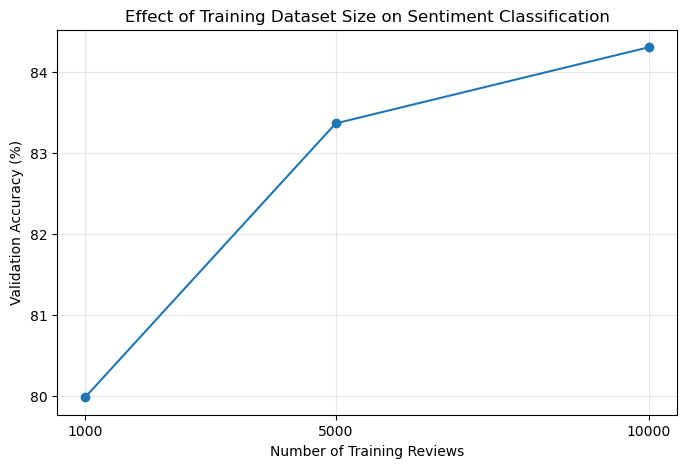

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    validation_results_df["Training_Size"],
    validation_results_df["Accuracy"] * 100,
    marker="o"
)

plt.xlabel("Number of Training Reviews")
plt.ylabel("Validation Accuracy (%)")
plt.title("Effect of Training Dataset Size on Sentiment Classification")
plt.xticks([1000, 5000, 10000])
plt.grid(True, alpha=0.3)

plt.savefig(
    save_folder / "training_size_vs_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Final evaluation on the official IMDb test set

Use the previously selected model once for the final reported evaluation. **Limitation:** the original exploratory notebook previously accessed a small sample of this test partition; therefore the test evaluation is not strictly untouched across the entire development history.

In [11]:
# Ensure the review column has the correct name
test_df = test_df.rename(columns={"Reviews": "Review"})

# Preprocess the official test dataset
test_df["Cleaned_Review"] = test_df["Review"].apply(prepare_review)

print("Test dataset shape:", test_df.shape)
print(test_df["Sentiment"].value_counts())

# Save so preprocessing does not need to be repeated
test_df.to_pickle(save_folder / "processed_test_df.pkl")

print("Processed test dataset saved.")

Test dataset shape: (25000, 3)
Sentiment
Positive    12500
Negative    12500
Name: count, dtype: int64
Processed test dataset saved.


In [12]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Retrieve our best validation model
final_vectorizer, final_model = trained_models[10000]

# Transform the official test reviews
X_final_test = final_vectorizer.transform(
    test_df["Cleaned_Review"]
)

y_final_test = test_df["Sentiment"]

# Predict
final_predictions = final_model.predict(X_final_test)

# Evaluate
final_accuracy = accuracy_score(
    y_final_test,
    final_predictions
)

print("Final test accuracy:", round(final_accuracy * 100, 2), "%")

print(classification_report(
    y_final_test,
    final_predictions
))

Final test accuracy: 83.23 %
              precision    recall  f1-score   support

    Negative       0.82      0.86      0.84     12500
    Positive       0.85      0.81      0.83     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000



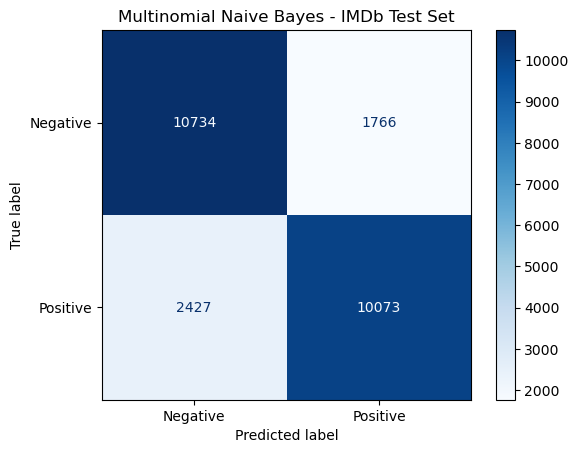

In [13]:
ConfusionMatrixDisplay.from_predictions(
    y_final_test,
    final_predictions,
    labels=["Negative", "Positive"],
    cmap="Blues",
    values_format="d"
)

plt.title("Multinomial Naive Bayes - IMDb Test Set")

plt.savefig(
    save_folder / "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. New review predictions and model persistence

In [14]:
new_reviews = [
    "This movie was amazing. I loved the story and the acting.",
    "The film was boring, and I regret watching it.",
    "The actors were excellent, but the ending was disappointing.",
    "I would definitely recommend this movie to my friends.",
    "This was not a good movie at all."
]

cleaned_reviews = [prepare_review(review) for review in new_reviews]

review_vectors = final_vectorizer.transform(cleaned_reviews)

predictions = final_model.predict(review_vectors)

for review, sentiment in zip(new_reviews, predictions):
    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print()

Review: This movie was amazing. I loved the story and the acting.
Predicted sentiment: Positive

Review: The film was boring, and I regret watching it.
Predicted sentiment: Negative

Review: The actors were excellent, but the ending was disappointing.
Predicted sentiment: Positive

Review: I would definitely recommend this movie to my friends.
Predicted sentiment: Positive

Review: This was not a good movie at all.
Predicted sentiment: Negative



In [15]:
import joblib

# Save the trained classifier
joblib.dump(
    final_model,
    save_folder / "sentiment_model.pkl"
)

# Save the TF-IDF vectorizer
joblib.dump(
    final_vectorizer,
    save_folder / "tfidf_vectorizer.pkl"
)

print("Model and vectorizer saved successfully.")

Model and vectorizer saved successfully.


In [16]:
loaded_model = joblib.load(
    save_folder / "sentiment_model.pkl"
)

loaded_vectorizer = joblib.load(
    save_folder / "tfidf_vectorizer.pkl"
)

example = "This movie was absolutely fantastic!"

cleaned_example = prepare_review(example)

example_features = loaded_vectorizer.transform(
    [cleaned_example]
)

prediction = loaded_model.predict(example_features)

print("Review:", example)
print("Prediction:", prediction[0])

Review: This movie was absolutely fantastic!
Prediction: Positive


## 7. Reproducibility and interpretation

The experiments were executed using three training dataset sizes (1,000, 5,000 and 10,000 reviews) and a fixed validation dataset of 5,000 reviews.

The reproduced validation accuracies were 79.98%, 83.36% and 84.30%, respectively. The final model achieved a test accuracy of 83.23% on 25,000 separate reviews. A fixed random state(random_state = 42) was used to support reproducibility.

The results show that increasing the training dataset size improved classification accuracy, even though the improvement become smaller as the dataset increased.